# Experimentos A/B sobre conjuntos de características

Se compara la misma tarea de clasificación con tres conjuntos de características. El modelo y la validación no cambian.

1. Datos y etiqueta.
2. Definición de F0, F1 y F2.
3. Validación y métricas.
4. Resultados comparados.
5. Gráficos.
6. Lectura y decisión.

Etiqueta: candidate_strategy (A1, A3, A5).
Modelo: regresión logística con pesos por clase.
Validación: cinco pliegues estratificados, semilla 42.
Métrica central: F1 macro.


In [1]:
from __future__ import annotations

from pathlib import Path
from time import perf_counter
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path("..").resolve()
DATA_PATH = ROOT / "data" / "processed" / "features" / "consultas_features.csv"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SPLITS = 5
TARGET = "candidate_strategy"


## 1. Datos y etiqueta

Fuente: data/processed/features/consultas_features.csv.
La etiqueta candidate_strategy es borrador del banco piloto. No es la ruta validada por expertos.


In [2]:
df = pd.read_csv(DATA_PATH)
y = df[TARGET].astype(str)

print("filas:", len(df))
print("clases:")
print(y.value_counts().sort_index().to_string())


filas: 196
clases:
candidate_strategy
A1    125
A3     27
A5     44


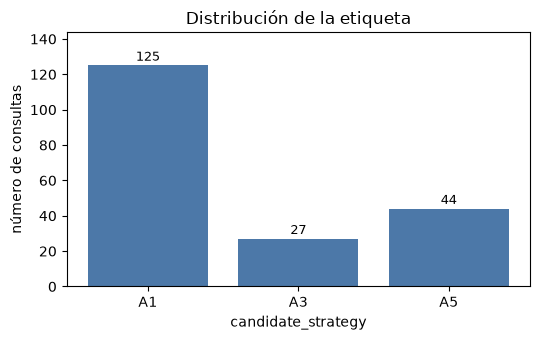

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
counts = y.value_counts().sort_index()
bars = ax.bar(counts.index.astype(str), counts.values, color="#4C78A8")
ax.set_xlabel("candidate_strategy")
ax.set_ylabel("número de consultas")
ax.set_title("Distribución de la etiqueta")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, str(v), ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.15)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana6_label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Definición de F0, F1 y F2

Cada variante añade un bloque de columnas. No se cambia el modelo.

| Variante | Columnas | Cambio |
|----------|----------|--------|
| Baseline F0 | forma del texto | línea base |
| Var1 F1 | F0 más tema léxico | añade intención |
| Var2 F2 | F1 más BM25 | añade búsqueda |

F2 usa puntuaciones de recuperación. Se interpreta como decisión después de una búsqueda barata, no como enrutamiento previo.


In [4]:
F0_NUM = [
    "query_length_chars",
    "query_length_words",
    "question_mark_count",
    "has_multiple_questions",
    "contains_negation",
    "contains_condition",
    "contains_comparison",
    "contains_personal_case",
]

F1_NUM = F0_NUM + [
    "n_intent_families",
    "requires_multiple_sources_rule",
    "requires_personal_context",
    "requires_calculation",
    "requires_rule_validation",
    "requires_temporal_reasoning",
    "contains_academic_entity",
    "contains_administrative_entity",
]
F1_CAT = ["intent_category"]

F2_NUM = F1_NUM + [
    "top1_retrieval_score",
    "topk_mean_score",
    "retrieval_score_margin",
    "retrieved_document_count",
    "retrieved_source_count",
]
F2_CAT = list(F1_CAT)

VARIANTES = {
    "Baseline_F0": {"num": F0_NUM, "cat": [], "nota": "solo forma del texto"},
    "Var1_F1": {"num": F1_NUM, "cat": F1_CAT, "nota": "texto más intención"},
    "Var2_F2": {"num": F2_NUM, "cat": F2_CAT, "nota": "intención más BM25"},
}

for nombre, spec in VARIANTES.items():
    faltan = [c for c in spec["num"] + spec["cat"] if c not in df.columns]
    assert not faltan, (nombre, faltan)
    print(f"{nombre}: {len(spec['num']) + len(spec['cat'])} columnas")


Baseline_F0: 8 columnas
Var1_F1: 17 columnas
Var2_F2: 22 columnas


## 3. Validación y métricas

1. StratifiedKFold con cinco pliegues.
2. Misma semilla en las tres variantes.
3. Escalado y one-hot solo dentro de cada pliegue de entrenamiento.
4. Métrica central: F1 macro.
5. Secundarias: F1 ponderado y exactitud.
6. Latencia: tiempo medio de entrenamiento y predicción por pliegue.


In [5]:
def armar_pipeline(num_cols: list[str], cat_cols: list[str]) -> Pipeline:
    bloques = []
    if num_cols:
        bloques.append(("num", StandardScaler(), num_cols))
    if cat_cols:
        bloques.append(
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
        )
    return Pipeline(
        [
            ("prep", ColumnTransformer(bloques)),
            (
                "modelo",
                LogisticRegression(
                    max_iter=2000,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    )


def evaluar(nombre: str, spec: dict[str, Any]) -> dict[str, Any]:
    cols = spec["num"] + spec["cat"]
    X = df[cols]
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    filas = []
    t_fit = []
    t_pred = []

    for k, (tr, te) in enumerate(cv.split(X, y), start=1):
        pipe = armar_pipeline(spec["num"], spec["cat"])
        t0 = perf_counter()
        pipe.fit(X.iloc[tr], y.iloc[tr])
        t_fit.append(perf_counter() - t0)
        t1 = perf_counter()
        y_hat = pipe.predict(X.iloc[te])
        t_pred.append(perf_counter() - t1)
        filas.append(
            {
                "experimento": nombre,
                "pliegue": k,
                "f1_macro": f1_score(y.iloc[te], y_hat, average="macro", zero_division=0),
                "f1_ponderado": f1_score(y.iloc[te], y_hat, average="weighted", zero_division=0),
                "exactitud": accuracy_score(y.iloc[te], y_hat),
                "fit_s": t_fit[-1],
                "predict_s": t_pred[-1],
                "nota": spec["nota"],
            }
        )

    pipe_oof = armar_pipeline(spec["num"], spec["cat"])
    y_oof = cross_val_predict(pipe_oof, X, y, cv=cv)
    return {
        "experimento": nombre,
        "nota": spec["nota"],
        "n_columnas": len(cols),
        "f1_macro_media": float(np.mean([f["f1_macro"] for f in filas])),
        "f1_macro_std": float(np.std([f["f1_macro"] for f in filas])),
        "f1_ponderado_media": float(np.mean([f["f1_ponderado"] for f in filas])),
        "exactitud_media": float(np.mean([f["exactitud"] for f in filas])),
        "fit_s_media": float(np.mean(t_fit)),
        "predict_s_media": float(np.mean(t_pred)),
        "latencia_s_media": float(np.mean(t_fit) + np.mean(t_pred)),
        "y_oof": y_oof,
        "pliegues": filas,
    }


resultados = [evaluar(n, s) for n, s in VARIANTES.items()]


## 4. Resultados comparados

Tabla resumen. La métrica central es F1 macro (media ± desviación entre pliegues).


In [6]:
tabla = pd.DataFrame(
    [
        {
            "experimento": r["experimento"],
            "nota": r["nota"],
            "columnas": r["n_columnas"],
            "f1_macro": f"{r['f1_macro_media']:.3f} ± {r['f1_macro_std']:.3f}",
            "f1_ponderado": f"{r['f1_ponderado_media']:.3f}",
            "exactitud": f"{r['exactitud_media']:.3f}",
            "fit_s": f"{r['fit_s_media']:.4f}",
            "predict_s": f"{r['predict_s_media']:.4f}",
        }
        for r in resultados
    ]
)
display(tabla)

pliegues = pd.DataFrame([f for r in resultados for f in r["pliegues"]])
log = tabla.copy()
log["semilla"] = SEED
log["pliegues_cv"] = N_SPLITS
log["etiqueta"] = TARGET
log["modelo"] = "LogisticRegression(class_weight=balanced)"
log["filas"] = len(df)
log.to_csv(LOG_DIR / "metrics_experimentos.csv", index=False)
pliegues.to_csv(LOG_DIR / "metrics_experimentos_folds.csv", index=False)


,experimento,nota,columnas,f1_macro,f1_ponderado,exactitud,fit_s,predict_s
0,Baseline_F0,solo forma del texto,8,0.474 ± 0.032,0.514,0.495,0.0049,0.0011
1,Var1_F1,texto más intención,17,0.533 ± 0.046,0.622,0.602,0.0065,0.0018
2,Var2_F2,intención más BM25,22,0.511 ± 0.061,0.595,0.577,0.0066,0.0017


## 5. Gráficos

### 5.1 F1 macro por variante

Barras con la media y la dispersión entre pliegues.


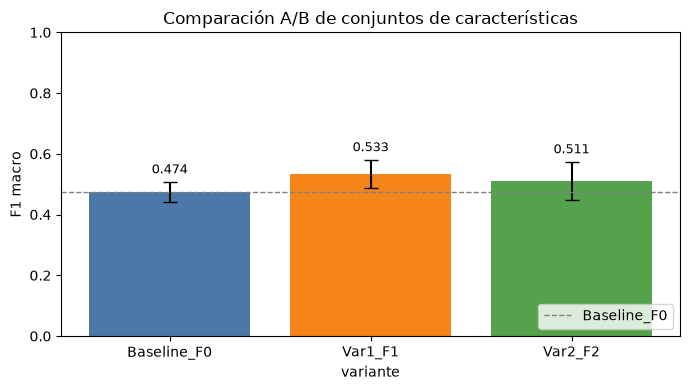

In [7]:
nombres = [r["experimento"] for r in resultados]
medias = [r["f1_macro_media"] for r in resultados]
stds = [r["f1_macro_std"] for r in resultados]
colores = ["#4C78A8", "#F58518", "#54A24B"]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(nombres))
ax.bar(x, medias, yerr=stds, capsize=5, color=colores)
ax.axhline(medias[0], color="gray", linestyle="--", linewidth=1, label="Baseline_F0")
ax.set_xticks(x)
ax.set_xticklabels(nombres)
ax.set_ylabel("F1 macro")
ax.set_xlabel("variante")
ax.set_title("Comparación A/B de conjuntos de características")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
for i, (m, s) in enumerate(zip(medias, stds)):
    ax.text(i, m + s + 0.02, f"{m:.3f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana6_ab_f1_barras.png", dpi=150, bbox_inches="tight")
plt.show()


### 5.2 F1 macro por pliegue

Cada punto es un pliegue. Sirve para ver si la media viene de un solo pliegue raro.


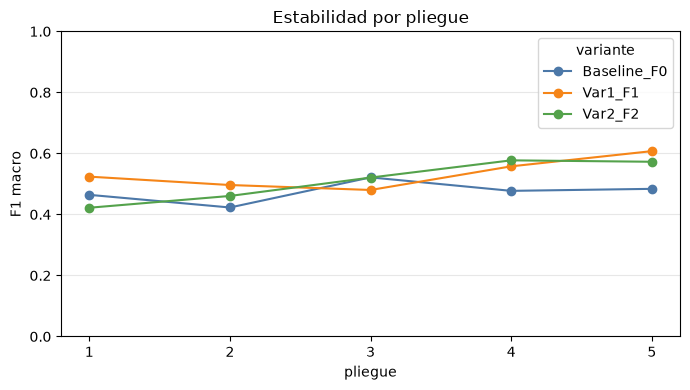

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for r, color in zip(resultados, colores):
    xs = [f["pliegue"] for f in r["pliegues"]]
    ys = [f["f1_macro"] for f in r["pliegues"]]
    ax.plot(xs, ys, marker="o", label=r["experimento"], color=color)
ax.set_xlabel("pliegue")
ax.set_ylabel("F1 macro")
ax.set_title("Estabilidad por pliegue")
ax.set_xticks(range(1, N_SPLITS + 1))
ax.set_ylim(0, 1)
ax.legend(title="variante")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana6_ab_f1_por_pliegue.png", dpi=150, bbox_inches="tight")
plt.show()


### 5.3 Matriz de confusión de la mejor variante

Predicciones fuera de pliegue con la misma validación cruzada.


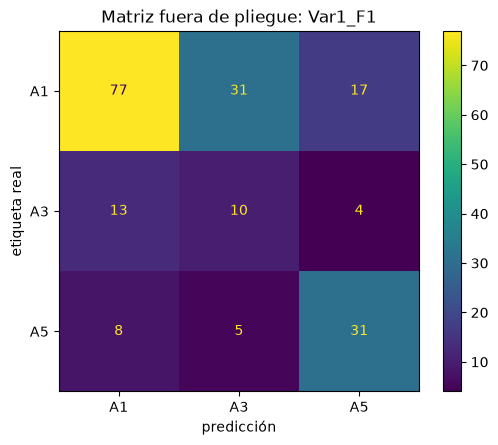

mejor variante: Var1_F1


In [9]:
mejor = max(resultados, key=lambda r: r["f1_macro_media"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y,
    mejor["y_oof"],
    ax=ax,
    colorbar=True,
)
ax.set_title(f"Matriz fuera de pliegue: {mejor['experimento']}")
ax.set_xlabel("predicción")
ax.set_ylabel("etiqueta real")
fig.tight_layout()
fig.savefig(FIG_DIR / "semana6_ab_confusion_mejor.png", dpi=150, bbox_inches="tight")
plt.show()
print("mejor variante:", mejor["experimento"])


## 6. Lectura y decisión

Qué se observa:

1. F0 queda abajo. Solo la forma del texto no alcanza para separar A1, A3 y A5.
2. F1 sube el F1 macro. El bloque de intención aporta más que la longitud o las marcas de texto.
3. F2 no mejora a F1 en este piloto. Las puntuaciones BM25 no agregan señal útil para esta etiqueta, o el índice no discrimina bien (mucho FAQ y D012).
4. La clase A1 domina el banco. Por eso se reporta F1 macro y no solo exactitud.
5. Los tiempos de entrenamiento y predicción casi no cambian entre variantes.

Decisión de este sprint: adoptar Var1_F1 como conjunto de características para el clasificador de ruta esperada. Descartar F2 para esta etiqueta hasta revisar la recuperación.

Límites:

- candidate_strategy es borrador.
- 196 filas; las clases A3 y A5 son pequeñas.
- F2 no se lee como enrutamiento previo a recuperar documentos.

Siguiente paso útil: repetir con etiquetas revisadas, o probar GroupKFold por origen si las FAQ se parecen entre sí.
